# APF2 — Sentilytics

Comparación experimental:

- APF1: TF-IDF + Regresión Logística balanced.
- APF2: Sentence-BERT congelado + Regresión Logística balanced.

Se conservan exactamente las mismas particiones de entrenamiento,
validación y test interno (mismos `review_id`), la misma regla de
decisión y el mismo criterio de umbral.

Todas las métricas de este notebook son de **validación**. El test
interno no se evalúa aquí: se reserva para
`grupo1_evaluacion_final.ipynb`.

In [1]:
!pip -q install sentence-transformers joblib

In [2]:
import json
import time
import joblib
import sklearn
import sentence_transformers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sentence_transformers import SentenceTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## Recuperación de datos

No se crea una nueva división. Se recuperan exactamente los mismos
textos e identificadores empleados en APF1.

In [3]:
# ============================================================
# RECUPERAR LAS PARTICIONES DE APF1 DESDE GOOGLE DRIVE
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

RUTA_APF1 = Path(
    "/content/drive/MyDrive/Sentilytics/APF1"
)

assert RUTA_APF1.exists(), (
    "No se encontró la carpeta Sentilytics/APF1 en Google Drive. "
    "Ejecutar primero grupo1apf1.ipynb."
)

archivos_necesarios = [
    "train.csv",
    "validacion.csv",
    "test_reservado.csv",
    "configuracion.json",
    "probabilidades_validacion.csv"
]

for nombre in archivos_necesarios:
    assert (RUTA_APF1 / nombre).exists(), (
        f"No se encontró el archivo: {nombre}"
    )

train = pd.read_csv(RUTA_APF1 / "train.csv")
val = pd.read_csv(RUTA_APF1 / "validacion.csv")
test = pd.read_csv(RUTA_APF1 / "test_reservado.csv")

print("Datos de APF1 recuperados correctamente.")
print("Train:", train.shape)
print("Validación:", val.shape)
print("Test reservado (no se evalúa aquí):", test.shape)

Mounted at /content/drive
Datos de APF1 recuperados correctamente.
Train: (720, 5)
Validación: (154, 5)
Test reservado (no se evalúa aquí): (155, 5)


## Verificación experimental

Los conjuntos no deben compartir reseñas. Esto evita que el modelo
sea evaluado con textos que ya observó durante el entrenamiento.

In [4]:
assert set(train["review_id"]).isdisjoint(val["review_id"])
assert set(train["review_id"]).isdisjoint(test["review_id"])
assert set(val["review_id"]).isdisjoint(test["review_id"])

assert train["review_id"].is_unique
assert val["review_id"].is_unique
assert test["review_id"].is_unique

print("Particiones verificadas: no existen IDs compartidos.")

Particiones verificadas: no existen IDs compartidos.


In [5]:
vectorizador_tfidf = joblib.load(
    RUTA_APF1 / "vectorizador_tfidf.joblib"
)

modelo_tfidf = joblib.load(
    RUTA_APF1 / "regresion_logistica.joblib"
)

with open(RUTA_APF1 / "configuracion.json", encoding="utf-8") as archivo:
    configuracion_apf1 = json.load(archivo)

SEMILLA = configuracion_apf1["semilla"]
np.random.seed(SEMILLA)

umbral_tfidf = configuracion_apf1["umbral_negativo"]

cantidades = configuracion_apf1["cantidad_datos"]
assert len(train) == cantidades["n_train"]
assert len(val) == cantidades["n_validacion"]
assert len(test) == cantidades["n_test"]

print("Baseline APF1 recuperado.")
print("Semilla:", SEMILLA)
print("Umbral TF-IDF (P(negativa) >=):", umbral_tfidf)

Baseline APF1 recuperado.
Semilla: 42
Umbral TF-IDF (P(negativa) >=): 0.48


## Encoder contextual

Sentence-BERT recibe `texto_contextual`: el texto original, con
puntuación y mayúsculas, no el texto preprocesado de TF-IDF. Genera un
vector contextual por reseña.

El encoder permanecerá congelado: no se realizará fine-tuning. Solo se
entrena la Regresión Logística sobre los embeddings.

In [6]:
NOMBRE_ENCODER = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

encoder = SentenceTransformer(NOMBRE_ENCODER)

print("Encoder cargado:", NOMBRE_ENCODER)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 9.08MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Encoder cargado: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2


## Generación de embeddings

In [7]:
def generar_embeddings(textos):
    return encoder.encode(
        textos.astype(str).tolist(),
        batch_size=32,
        show_progress_bar=True,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

inicio = time.perf_counter()
E_train = generar_embeddings(train["texto_contextual"])
E_val   = generar_embeddings(val["texto_contextual"])
segundos_embeddings = time.perf_counter() - inicio

y_train = train["sentimiento"].to_numpy()
y_val   = val["sentimiento"].to_numpy()

longitudes_tokens = [
    len(encoder.tokenizer(texto)["input_ids"])
    for texto in pd.concat([train, val])["texto_contextual"]
]
resenas_truncadas = int(sum(
    n > encoder.max_seq_length for n in longitudes_tokens
))

print("Embeddings de entrenamiento:", E_train.shape)
print("Embeddings de validación:", E_val.shape)
print(f"Tiempo de codificación (train + validación): "
      f"{segundos_embeddings:.1f} s en {encoder.device}")
print("Longitud máxima del encoder:", encoder.max_seq_length, "tokens")
print("Reseñas truncadas (train + validación):", resenas_truncadas)

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Batches:   0%|          | 0/5 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (139 > 128). Running this sequence through the model will result in indexing errors


Embeddings de entrenamiento: (720, 384)
Embeddings de validación: (154, 384)
Tiempo de codificación (train + validación): 32.5 s en cpu
Longitud máxima del encoder: 128 tokens
Reseñas truncadas (train + validación): 2


## Entrenamiento de APF2

Sentence-BERT no se entrena. La Regresión Logística aprende a
relacionar los embeddings con las clases negativa y positiva.

In [8]:
modelo_sbert = LogisticRegression(
    C=1.0,
    class_weight="balanced",
    max_iter=1000,
    random_state=SEMILLA
)

modelo_sbert.fit(E_train, y_train)

print("Regresión Logística entrenada con embeddings contextuales.")

Regresión Logística entrenada con embeddings contextuales.


## Selección del umbral con validación

Se aplica exactamente la misma función, rejilla y criterio que en APF1:
probabilidad de la clase 0 (vía `classes_`), maximizar recall negativo
con precisión negativa >= 0.60, desempate por F1 negativo y luego por
cercanía a 0.50.

In [9]:
REJILLA_UMBRAL = np.round(np.arange(0.30, 0.701, 0.02), 2)

PRECISION_NEGATIVA_MINIMA = 0.60

CRITERIO_UMBRAL = (
    "Maximizar recall negativo en validación con precisión negativa "
    f">= {PRECISION_NEGATIVA_MINIMA:.2f} (tope de falsas alarmas); "
    "desempate por mayor F1 negativo y luego por el umbral más cercano "
    "a 0.50. Si ningún umbral cumple la restricción, se maximiza F1 "
    "negativo."
)


def seleccionar_umbral(y_real, prob_negativa, rejilla=REJILLA_UMBRAL):
    """Una reseña se marca como negativa (0) si prob_negativa >= umbral.
    Debe ser idéntica en los tres pipelines."""
    filas = []

    for umbral in rejilla:
        pred = np.where(prob_negativa >= umbral, 0, 1)

        filas.append({
            "umbral_negativo": float(umbral),
            "precision_negativa": precision_score(
                y_real, pred, pos_label=0, zero_division=0
            ),
            "recall_negativo": recall_score(
                y_real, pred, pos_label=0, zero_division=0
            ),
            "f1_negativo": f1_score(
                y_real, pred, pos_label=0, zero_division=0
            ),
            "f1_macro": f1_score(
                y_real, pred, average="macro", zero_division=0
            ),
            "alertas_generadas": int((pred == 0).sum())
        })

    tabla = pd.DataFrame(filas)
    tabla["cumple_precision"] = (
        tabla["precision_negativa"] >= PRECISION_NEGATIVA_MINIMA
    )
    tabla["distancia_050"] = (tabla["umbral_negativo"] - 0.50).abs()

    candidatos = tabla[tabla["cumple_precision"]]

    if candidatos.empty:
        mejor = tabla.sort_values(
            ["f1_negativo", "distancia_050"],
            ascending=[False, True]
        ).iloc[0]
    else:
        mejor = candidatos.sort_values(
            ["recall_negativo", "f1_negativo", "distancia_050"],
            ascending=[False, False, True]
        ).iloc[0]

    return (
        float(mejor["umbral_negativo"]),
        tabla.drop(columns="distancia_050")
    )


assert REJILLA_UMBRAL.tolist() == configuracion_apf1["rejilla_umbral"]
assert CRITERIO_UMBRAL == configuracion_apf1["criterio_umbral"]

idx_negativa_sbert = list(modelo_sbert.classes_).index(0)

prob_val_neg_sbert = modelo_sbert.predict_proba(
    E_val
)[:, idx_negativa_sbert]

umbral_sbert, tabla_umbrales = seleccionar_umbral(
    y_val, prob_val_neg_sbert
)

display(tabla_umbrales.round(4))
print("Umbral seleccionado con validación (P(negativa) >=):", umbral_sbert)

,umbral_negativo,precision_negativa,recall_negativo,f1_negativo,f1_macro,alertas_generadas,cumple_precision
0,0.30,0.5556,0.9615,0.7042,0.8078,45,False
1,0.32,0.5814,0.9615,0.7246,0.8226,43,False
2,0.34,0.5952,0.9615,0.7353,0.8301,42,False
3,0.36,0.6579,0.9615,0.7812,0.8619,38,True
4,0.38,0.6579,0.9615,0.7812,0.8619,38,True
5,0.40,0.6757,0.9615,0.7937,0.8703,37,True
6,0.42,0.6757,0.9615,0.7937,0.8703,37,True
7,0.44,0.6944,0.9615,0.8065,0.8788,36,True
8,0.46,0.6944,0.9615,0.8065,0.8788,36,True
9,0.48,0.7143,0.9615,0.8197,0.8876,35,True


Umbral seleccionado con validación (P(negativa) >=): 0.48


## Función de evaluación

Los conteos se definen respecto a la detección de la clase negativa:
VP = queja detectada, FN = queja omitida, FP = falsa alarma.

In [10]:
def calcular_metricas(y_real, y_predicho):
    # labels=[1, 0]: la clase a detectar es la negativa (0)
    vn, fp, fn, vp = confusion_matrix(
        y_real, y_predicho, labels=[1, 0]
    ).ravel()

    return {
        "accuracy": accuracy_score(y_real, y_predicho),
        "balanced_accuracy": balanced_accuracy_score(
            y_real, y_predicho
        ),
        "precision_negativa": precision_score(
            y_real, y_predicho, pos_label=0, zero_division=0
        ),
        "recall_negativo": recall_score(
            y_real, y_predicho, pos_label=0, zero_division=0
        ),
        "f1_negativo": f1_score(
            y_real, y_predicho, pos_label=0, zero_division=0
        ),
        "f1_macro": f1_score(
            y_real, y_predicho, average="macro", zero_division=0
        ),
        "quejas_detectadas_VP": int(vp),
        "quejas_omitidas_FN": int(fn),
        "falsas_alarmas_FP": int(fp),
        "positivas_correctas_VN": int(vn),
        "soporte_negativo": int(vp + fn)
    }

## Comparación de APF1 y APF2 en validación

In [11]:
# APF1: TF-IDF
X_val_tfidf = vectorizador_tfidf.transform(
    val["texto_tfidf"]
)

idx_negativa_tfidf = list(modelo_tfidf.classes_).index(0)

prob_val_neg_tfidf = modelo_tfidf.predict_proba(
    X_val_tfidf
)[:, idx_negativa_tfidf]

probabilidades_apf1 = pd.read_csv(
    RUTA_APF1 / "probabilidades_validacion.csv"
)
assert (probabilidades_apf1["review_id"].to_numpy()
        == val["review_id"].to_numpy()).all()
assert np.allclose(
    probabilidades_apf1["prob_negativa"], prob_val_neg_tfidf
), "Las probabilidades TF-IDF no coinciden con las guardadas en APF1."

pred_val_tfidf = np.where(
    prob_val_neg_tfidf >= umbral_tfidf, 0, 1
)

# APF2: Sentence-BERT
pred_val_sbert = np.where(
    prob_val_neg_sbert >= umbral_sbert, 0, 1
)

comparacion_val = pd.DataFrame({
    "TF-IDF": calcular_metricas(
        y_val, pred_val_tfidf
    ),
    "Sentence-BERT": calcular_metricas(
        y_val, pred_val_sbert
    )
}).T

comparacion_val["umbral_negativo"] = [umbral_tfidf, umbral_sbert]

print("COMPARACIÓN EN VALIDACIÓN (no test)")
display(comparacion_val.round(4))

COMPARACIÓN EN VALIDACIÓN (no test)


,accuracy,balanced_accuracy,precision_negativa,recall_negativo,f1_negativo,f1_macro,quejas_detectadas_VP,quejas_omitidas_FN,falsas_alarmas_FP,positivas_correctas_VN,soporte_negativo,umbral_negativo
TF-IDF,0.8831,0.8377,0.6250,0.7692,0.6897,0.8088,20.0,6.0,12.0,116.0,26.0,0.48
Sentence-BERT,0.9286,0.9417,0.7143,0.9615,0.8197,0.8876,25.0,1.0,10.0,118.0,26.0,0.48


## Matrices de confusión (validación)

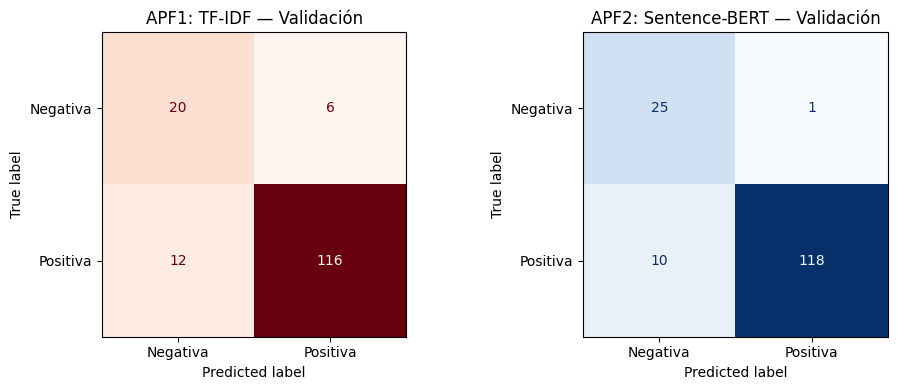

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    pred_val_tfidf,
    display_labels=["Negativa", "Positiva"],
    cmap="Reds",
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("APF1: TF-IDF — Validación")

ConfusionMatrixDisplay.from_predictions(
    y_val,
    pred_val_sbert,
    display_labels=["Negativa", "Positiva"],
    cmap="Blues",
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("APF2: Sentence-BERT — Validación")

plt.tight_layout()
plt.show()

## Análisis de errores apareado

Sobre las mismas reseñas de validación se identifican:

- **Casos corregidos:** TF-IDF se equivocó y Sentence-BERT acertó.
- **Regresiones:** TF-IDF acertó y Sentence-BERT se equivocó.

Se marcan las reseñas con negaciones (`no`, `nunca`, `sin`, `ni`) para
revisar si el modelo contextual las maneja mejor. La interpretación de
cada error debe apoyarse en ejemplos concretos; no se atribuyen errores
a ironía sin evidencia.

In [13]:
analisis = val[
    ["review_id", "texto_contextual", "sentimiento"]
].copy()

analisis["pred_tfidf"] = pred_val_tfidf
analisis["pred_sbert"] = pred_val_sbert
analisis["tiene_negacion"] = analisis["texto_contextual"].str.contains(
    r"\b(?:no|nunca|sin|ni)\b", case=False, regex=True
)

casos_corregidos = analisis[
    (analisis["pred_tfidf"] != analisis["sentimiento"]) &
    (analisis["pred_sbert"] == analisis["sentimiento"])
]

regresiones = analisis[
    (analisis["pred_tfidf"] == analisis["sentimiento"]) &
    (analisis["pred_sbert"] != analisis["sentimiento"])
]

errores_ambos = analisis[
    (analisis["pred_tfidf"] != analisis["sentimiento"]) &
    (analisis["pred_sbert"] != analisis["sentimiento"])
]

resumen_apareado = pd.DataFrame({
    "casos": [len(casos_corregidos), len(regresiones), len(errores_ambos)],
    "con_negacion": [
        int(casos_corregidos["tiene_negacion"].sum()),
        int(regresiones["tiene_negacion"].sum()),
        int(errores_ambos["tiene_negacion"].sum())
    ]
}, index=[
    "Corregidos por Sentence-BERT",
    "Regresiones de Sentence-BERT",
    "Errores de ambos modelos"
])

display(resumen_apareado)

print("\nCasos corregidos por Sentence-BERT:")
display(casos_corregidos)

print("\nRegresiones (TF-IDF acertó, Sentence-BERT no):")
display(regresiones)

print("\nErrores de ambos modelos:")
display(errores_ambos)

,casos,con_negacion
Corregidos por Sentence-BERT,15,6
Regresiones de Sentence-BERT,8,1
Errores de ambos modelos,3,1



Casos corregidos por Sentence-BERT:


,review_id,texto_contextual,sentimiento,pred_tfidf,pred_sbert,tiene_negacion
5,911,Estancia decepcionante,0,1,0,False
28,306,Inútil reclamar .,0,1,0,False
41,923,Personalmente adoro las alhomadas duspués de u...,1,0,1,False
43,564,"Las habitaciones son amplias , tienen una TV d...",1,0,1,False
44,319,"Bueno el hotel no era malo , estaba limpio y bien",1,0,1,True
71,863,La atencion un desastre,0,1,0,False
75,40,El desayuno el resto de los días genial el buf...,1,0,1,False
81,432,"como la vez anterior , no nos defraudó en nada .",1,0,1,True
93,945,Su cercanía con la Ciudad de las artes y las C...,1,0,1,False
101,1025,Para el precio que nos costo no estaba nada ma...,1,0,1,True



Regresiones (TF-IDF acertó, Sentence-BERT no):


,review_id,texto_contextual,sentimiento,pred_tfidf,pred_sbert,tiene_negacion
4,1014,Minibar gratuido,1,1,0,False
34,931,Pero había autobuses delante del hotel y parad...,1,1,0,False
52,278,Las parcelas son amplias y con mucha sombra .,1,1,0,False
60,817,"Como detalle mio personal , me enloquecen los ...",1,1,0,False
66,890,En esta ocasión no hemos utilizado el servicio...,1,1,0,True
95,675,"Una vez mas me he alojado en este hotel , he o...",1,1,0,False
102,490,Un 10 !,1,1,0,False
115,41,Sorpresa enorme,1,1,0,False



Errores de ambos modelos:


,review_id,texto_contextual,sentimiento,pred_tfidf,pred_sbert,tiene_negacion
33,465,Tiene unos precios bastante mas baratos en su ...,1,0,0,False
59,871,"Regular , podría mejorar .",0,1,1,False
90,566,"En Agosto hace calor y es temporada alta , per...",1,0,0,True


In [14]:
# ============================================================
# GUARDAR APF2 EN GOOGLE DRIVE
# ============================================================

RUTA_APF2 = Path(
    "/content/drive/MyDrive/Sentilytics/APF2"
)

RUTA_APF2.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    modelo_sbert,
    RUTA_APF2 / "regresion_logistica_sbert.joblib"
)

np.save(RUTA_APF2 / "embeddings_train.npy", E_train)
np.save(RUTA_APF2 / "embeddings_validacion.npy", E_val)

pd.DataFrame({
    "review_id": val["review_id"].to_numpy(),
    "sentimiento": y_val,
    "prob_negativa": prob_val_neg_sbert,
    "prediccion": pred_val_sbert
}).to_csv(RUTA_APF2 / "probabilidades_validacion.csv", index=False)

configuracion_apf2 = {
    "encoder": NOMBRE_ENCODER,
    "texto_entrada": "texto_contextual (original, con puntuación y mayúsculas)",
    "encoder_congelado": True,
    "normalize_embeddings": True,
    "dimension_embedding": int(E_train.shape[1]),
    "max_seq_length": int(encoder.max_seq_length),
    "resenas_truncadas_train_val": resenas_truncadas,
    "clasificador": {
        "tipo": "LogisticRegression",
        "C": 1.0,
        "class_weight": "balanced",
        "max_iter": 1000
    },
    "umbral_negativo": float(umbral_sbert),
    "regla_decision": "negativa (0) si P(negativa) >= umbral_negativo",
    "criterio_umbral": CRITERIO_UMBRAL,
    "rejilla_umbral": REJILLA_UMBRAL.tolist(),
    "segundos_embeddings_train_val": round(segundos_embeddings, 2),
    "dispositivo": str(encoder.device),
    "semilla": SEMILLA,
    "version_sentence_transformers": sentence_transformers.__version__,
    "version_sklearn": sklearn.__version__
}

with open(
    RUTA_APF2 / "configuracion_apf2.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        configuracion_apf2,
        archivo,
        ensure_ascii=False,
        indent=2
    )

comparacion_val.to_csv(
    RUTA_APF2 / "comparacion_validacion.csv",
    index=True
)

print("APF2 guardado correctamente en Google Drive.")
print("Ubicación:", RUTA_APF2)

APF2 guardado correctamente en Google Drive.
Ubicación: /content/drive/MyDrive/Sentilytics/APF2


## Test interno reservado

Este notebook no evalúa el test interno.

**Declaración:** en una ejecución anterior de este notebook (cierre de
APF2) se calculó una vez el desempeño de TF-IDF y Sentence-BERT sobre el
test interno. Ese resultado no se utilizó para ninguna decisión
(limpieza, hiperparámetros, umbral ni elección de modelo) y queda
declarado en el informe.

Para disponer además de una evaluación no consultada, la comparación
final incluye el split oficial `test` de
`mteb/SpanishSentimentClassification`, previa auditoría de
solapamientos. Ambas evaluaciones se ejecutan una sola vez en
`grupo1_evaluacion_final.ipynb`, cuando los tres pipelines estén
cerrados.